# Alta e reversão em criptomoedas com LightGBM

O notebook lê os arquivos `data/archive/coin_*.csv` e simula uma triagem **no fechamento diário**. O agente primeiro identifica uma alta acompanhada de volume elevado. Em seguida, estima o risco de reversão nos três fechamentos seguintes. Os rótulos vêm de uma regra aplicada aos preços observados, sem gerar preços artificiais.

A combinação de alta, volume e queda posterior se inspira em Kamps e Kleinberg. Esta adaptação diária mede um padrão de mercado. A confirmação de manipulação exige evidências externas e a agregação diária oculta movimentos que ocorreram e se reverteram antes do fechamento. [Kamps e Kleinberg (2018)](https://doi.org/10.1186/s40163-018-0093-5) · [Guia do monitor intradiário do OONCA](../docs/pump-dump-agent.md)

Na raiz do projeto, instale `requirements.txt` e os pacotes `jupyterlab` e `matplotlib`. Abra o notebook e execute todas as células. Para trocar a fonte, ajuste `DATA_DIR` e mantenha as colunas `Symbol,Date,Open,High,Low,Close,Volume`.

In [1]:
from pathlib import Path
from typing import TypedDict

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from langgraph.graph import END, START, StateGraph
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve
from sklearn.utils.class_weight import compute_sample_weight

cwd = Path.cwd().resolve()
root = next((path for path in (cwd, *cwd.parents) if (path / "app/models/pump_dump.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Abra o notebook a partir do repositório do OONCA.")

DATA_DIR = root / "data/archive"
RALLY_MIN = 0.15
VOLUME_MIN = 2.0
VOLUME_LOOKBACK = 30
REVERSAL_MIN = 0.15
HORIZON = 3
VALID_FROM = pd.Timestamp("2018-01-01", tz="UTC")
TEST_FROM = pd.Timestamp("2020-07-01", tz="UTC")
EXCLUDED = {"USDT", "USDC", "WBTC"}

BLUE, TEAL, ORANGE = "#2457a6", "#087f7d", "#bd4e20"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#dde5ee",
    "grid.alpha": 0.75, "font.size": 10,
})

## 1. Carregar e alinhar o OHLCV

Cada linha representa um dia por ativo. Interpretamos as datas como dias UTC e mantemos as lacunas no calendário, sem preencher preços ou volumes ausentes. Volumes iguais a zero ficam indisponíveis para o cálculo do volume relativo. Excluímos USDC e USDT porque desancoragem é outro desfecho. Excluímos WBTC para evitar contar uma segunda exposição a BTC.

In [2]:
COLUMNS = ["Symbol", "Date", "Open", "High", "Low", "Close", "Volume"]
paths = sorted(DATA_DIR.glob("coin_*.csv"))
if not paths:
    raise FileNotFoundError(f"Coloque os arquivos coin_*.csv em {DATA_DIR}.")

raw = pd.concat([pd.read_csv(path, usecols=COLUMNS) for path in paths], ignore_index=True)
raw = raw.rename(columns=str.lower)
raw["symbol"] = raw["symbol"].astype("string").str.strip().str.upper()
raw["date"] = pd.to_datetime(raw["date"], format="ISO8601", utc=True).dt.normalize()
if raw[["symbol", "date"]].isna().any().any() or raw["symbol"].eq("").any():
    raise ValueError("Preencha o símbolo e a data de cada candle.")
if raw.duplicated(["symbol", "date"]).any():
    raise ValueError("Há mais de um candle para o mesmo ativo e dia.")

price_columns = ["open", "high", "low", "close"]
numeric_columns = [*price_columns, "volume"]
raw[numeric_columns] = raw[numeric_columns].apply(pd.to_numeric, errors="raise")
raw[numeric_columns] = raw[numeric_columns].where(raw[numeric_columns].gt(0)).replace([np.inf], np.nan)

assets = raw.loc[~raw["symbol"].isin(EXCLUDED)]
print(f"{len(paths)} arquivos · {len(raw):,} candles · {assets['symbol'].nunique()} ativos analisados")
print(f"Cobertura do acervo de {raw['date'].min():%d/%m/%Y} a {raw['date'].max():%d/%m/%Y} UTC")

23 arquivos · 37,082 candles · 20 ativos analisados
Cobertura do acervo de 29/04/2013 a 06/07/2021 UTC


## 2. Gerar sinais disponíveis no fechamento

O gatilho exige retorno de fechamento a fechamento de **15% ou mais** e volume do dia de **pelo menos 2× a mediana dos 30 dias anteriores**. Esses limites são parâmetros exploratórios definidos para o notebook.

O LightGBM usa os retornos de 1, 3 e 7 dias, o retorno diário acima do BTC, a volatilidade prévia, a amplitude do candle, a posição do fechamento dentro dele e o volume relativo. O retorno acima do BTC é a diferença entre os dois retornos no mesmo dia, sem estimar beta de mercado.

In [3]:
FEATURE_NAMES = {
    "return_1d": "Retorno em 1 dia",
    "return_3d": "Retorno em 3 dias",
    "return_7d": "Retorno em 7 dias",
    "excess_btc": "Retorno menos BTC",
    "relative_volume": "Volume relativo",
    "volatility_14d": "Volatilidade prévia em 14 dias",
    "range_pct": "Amplitude do candle",
    "close_position": "Posição do fechamento",
}
FEATURES = list(FEATURE_NAMES)


def daily_signals(group):
    frame = group.set_index("date").sort_index().asfreq("D")
    for days in (1, 3, 7):
        returns = frame["close"].div(frame["close"].shift(days)).sub(1)
        complete = frame["close"].rolling(days + 1).count().eq(days + 1)
        frame[f"return_{days}d"] = returns.where(complete)
    typical_volume = frame["volume"].shift().rolling(VOLUME_LOOKBACK).median()
    frame["relative_volume"] = frame["volume"].div(typical_volume)
    frame["volatility_14d"] = frame["return_1d"].shift().rolling(14).std()
    spread = frame["high"] - frame["low"]
    frame["range_pct"] = spread.div(frame["open"]).where(spread.ge(0))
    frame["close_position"] = frame["close"].sub(frame["low"]).div(spread.where(spread.gt(0)))
    frame["candidate"] = frame["return_1d"].ge(RALLY_MIN) & frame["relative_volume"].ge(VOLUME_MIN)
    return frame.reset_index()


panel = pd.concat(
    [daily_signals(group).assign(symbol=symbol) for symbol, group in assets.groupby("symbol")],
    ignore_index=True,
)
btc_returns = panel.loc[panel["symbol"].eq("BTC")].set_index("date")["return_1d"]
if btc_returns.empty:
    raise ValueError("Inclua a série de BTC como referência de mercado.")
panel["excess_btc"] = panel["return_1d"] - panel["date"].map(btc_returns)
panel["scorable"] = np.isfinite(panel[FEATURES]).all(axis=1)
print(f"{panel['candidate'].sum()} dias-ativo acionaram o gatilho.")

635 dias-ativo acionaram o gatilho.


## 3. Rotular a reversão e separar os períodos

Para um candidato no dia `t`, o rótulo vale **1** se algum fechamento entre `t+1` e `t+3` cair **15% ou mais** abaixo do fechamento de `t`. Vale **0** se os três fechamentos estão disponíveis e nenhum cruza o limite. As últimas datas e os horizontes com lacunas ficam sem rótulo.

A separação é por data, em todos os ativos ao mesmo tempo. O treino e a validação descartam observações cujos rótulos dependeriam de preços do período seguinte. Os fechamentos futuros são usados para construir e verificar o rótulo. Eles ficam fora das features e do agente.

In [4]:
by_symbol = panel.groupby("symbol", sort=False)["close"]
future_closes = pd.DataFrame({day: by_symbol.shift(-day) for day in range(1, HORIZON + 1)})
panel["future_return"] = (
    future_closes.min(axis=1).div(panel["close"]).sub(1)
    .where(future_closes.notna().all(axis=1))
)
label_available = panel["candidate"] & panel["future_return"].notna()
panel["label"] = panel["future_return"].le(-REVERSAL_MIN).where(label_available).astype("Int8")
panel["label_end"] = panel["date"] + pd.Timedelta(days=HORIZON)

eligible = panel.loc[panel["scorable"] & panel["label"].notna()].copy()
eligible["label"] = eligible["label"].astype(int)
train = eligible.loc[eligible["label_end"].lt(VALID_FROM)]
validation = eligible.loc[eligible["date"].ge(VALID_FROM) & eligible["label_end"].lt(TEST_FROM)]
test = eligible.loc[eligible["date"].ge(TEST_FROM)].copy()

splits = {"Treino": train, "Validação": validation, "Teste": test}
for name, sample in splits.items():
    if sample["label"].nunique() < 2:
        raise ValueError(f"{name} precisa conter reversões e não reversões. Revise os cortes e a cobertura.")

display(pd.DataFrame({
    name: {
        "Primeira data": sample["date"].min().date(),
        "Última data": sample["date"].max().date(),
        "Candidatos com rótulo": len(sample),
        "Reversões": int(sample["label"].sum()),
    }
    for name, sample in splits.items()
}).T)
print(f"Candidatos sem cobertura de features ou do desfecho: {panel['candidate'].sum() - len(eligible)}.")
print(f"Candidatos retirados nos cortes temporais: {len(eligible) - sum(map(len, splits.values()))}.")

,Primeira data,Última data,Candidatos com rótulo,Reversões
Treino,2014-01-29,2017-12-27,335,62
Validação,2018-01-01,2020-05-30,125,14
Teste,2020-07-08,2021-06-23,170,30


Candidatos sem cobertura de features ou do desfecho: 0.
Candidatos retirados nos cortes temporais: 5.


## 4. Treinar e comparar com uma regra simples

O LightGBM aprende a distinguir quais altas com volume elevado foram seguidas de reversão. Os pesos balanceados vêm apenas do treino. O limiar de alerta maximiza F1 na validação e fica fixo para o teste. O score é uma medida de ordenação sem calibração probabilística.

Comparamos o resultado com duas referências. A primeira emite alerta para todo candidato. A segunda ordena os candidatos apenas pelo tamanho da alta do dia. As métricas abaixo se referem aos candidatos com desfecho observável.

In [5]:
model = LGBMClassifier(
    objective="binary", n_estimators=200, max_depth=4, num_leaves=16,
    min_child_samples=6, random_state=42, verbosity=-1,
)
model.fit(train[FEATURES], train["label"], sample_weight=compute_sample_weight("balanced", train["label"]))

validation_scores = model.predict_proba(validation[FEATURES])[:, 1]
precision, recall, thresholds = precision_recall_curve(validation["label"], validation_scores)
p, r = precision[:-1], recall[:-1]
f1 = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
threshold = float(thresholds[np.flatnonzero(f1 == f1.max())[-1]])

test["score"] = model.predict_proba(test[FEATURES])[:, 1]
test["alert"] = test["score"].ge(threshold)
actual = test["label"].eq(1)
matrix = confusion_matrix(actual, test["alert"], labels=[False, True])
tn, fp, fn, tp = matrix.ravel()
prevalence = float(actual.mean())

comparison = pd.DataFrame([
    {
        "Método": "LightGBM", "Alertas": int(tp + fp), "Acertos": int(tp),
        "Precisão": tp / max(tp + fp, 1), "Revocação": tp / (tp + fn),
        "AP": average_precision_score(actual, test["score"]),
    },
    {
        "Método": "Alertar todos os candidatos", "Alertas": len(test), "Acertos": int(actual.sum()),
        "Precisão": prevalence, "Revocação": 1.0, "AP": prevalence,
    },
    {
        "Método": "Ordenar pela alta do dia", "Alertas": pd.NA, "Acertos": pd.NA,
        "Precisão": np.nan, "Revocação": np.nan,
        "AP": average_precision_score(actual, test["return_1d"]),
    },
]).set_index("Método")
display(comparison.round(3))
print(f"Limiar escolhido na validação: {threshold:.3g}. Máximo F1 na validação: {f1.max():.3f}.")
print(f"O LightGBM sinalizou {tp + fp}/{len(test)} candidatos e capturou {tp}/{tp + fn} reversões.")
best_ap = comparison["AP"].idxmax()
print(f"Maior AP no teste: {best_ap} ({comparison.loc[best_ap, 'AP']:.3f}).")

,Alertas,Acertos,Precisão,Revocação,AP
Método,,,,,
LightGBM,157,28,0.178,0.933,0.221
Alertar todos os candidatos,170,30,0.176,1.000,0.176
Ordenar pela alta do dia,<NA>,<NA>,NaN,NaN,0.353


Limiar escolhido na validação: 0.00209. Máximo F1 na validação: 0.243.
O LightGBM sinalizou 157/170 candidatos e capturou 28/30 reversões.
Maior AP no teste: Ordenar pela alta do dia (0.353).


## 5. Inspecionar o resultado

O gráfico de mercado mostra a primeira reversão rotulada no teste, escolhida para ilustrar a regra. A área sombreada cobre o horizonte futuro, que só entra na análise retrospectiva. A matriz de confusão e a curva precisão–revocação usam todos os candidatos do teste.

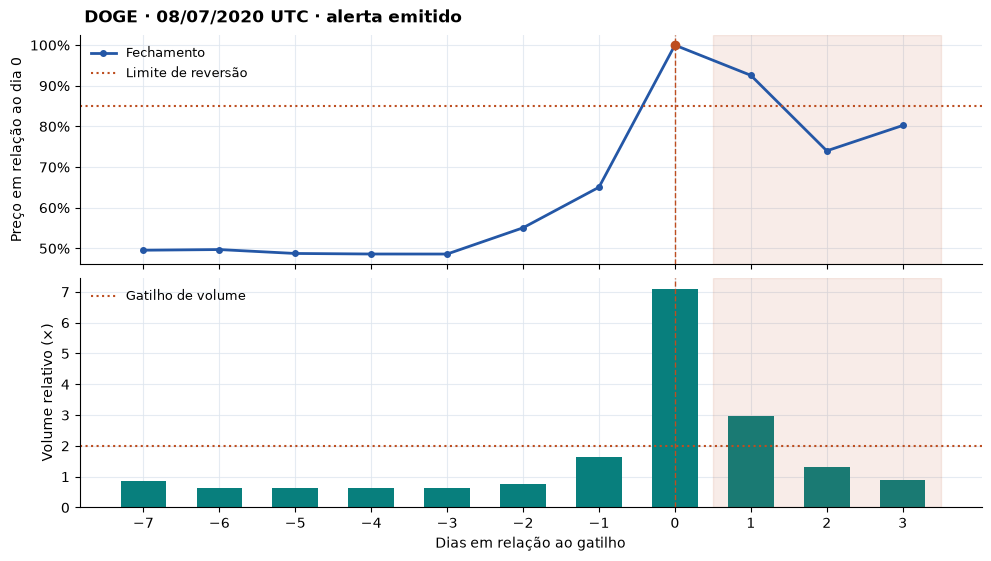

In [6]:
example = test.loc[actual].sort_values(["date", "symbol"]).iloc[0]
day, symbol = example["date"], example["symbol"]
window = panel.loc[
    panel["symbol"].eq(symbol)
    & panel["date"].between(day - pd.Timedelta(days=7), day + pd.Timedelta(days=HORIZON))
].copy()
offset = (window["date"] - day).dt.days
indexed_close = window["close"] / example["close"]
status = "alerta emitido" if example["alert"] else "sem alerta"

fig, (price_ax, volume_ax) = plt.subplots(2, 1, figsize=(9.8, 5.5), sharex=True, layout="constrained")
fig.suptitle(f"{symbol} · {day:%d/%m/%Y} UTC · {status}", x=0.08, ha="left", weight="bold")
price_ax.plot(offset, indexed_close, marker="o", ms=4, lw=2, color=BLUE, label="Fechamento")
price_ax.scatter([0], [1], color=ORANGE, zorder=4)
price_ax.axhline(1 - REVERSAL_MIN, ls=":", color=ORANGE, label="Limite de reversão")
price_ax.yaxis.set_major_formatter(PercentFormatter(1))
price_ax.set_ylabel("Preço em relação ao dia 0")
price_ax.legend(loc="best", frameon=False, fontsize=9)

volume_ax.bar(offset, window["relative_volume"], width=0.6, color=TEAL)
volume_ax.axhline(VOLUME_MIN, ls=":", color=ORANGE, label="Gatilho de volume")
volume_ax.set(xlabel="Dias em relação ao gatilho", ylabel="Volume relativo (×)", xticks=offset)
volume_ax.legend(loc="best", frameon=False, fontsize=9)
for ax in (price_ax, volume_ax):
    ax.axvspan(0.5, HORIZON + 0.5, color=ORANGE, alpha=0.10)
    ax.axvline(0, ls="--", color=ORANGE, lw=1)
plt.show()

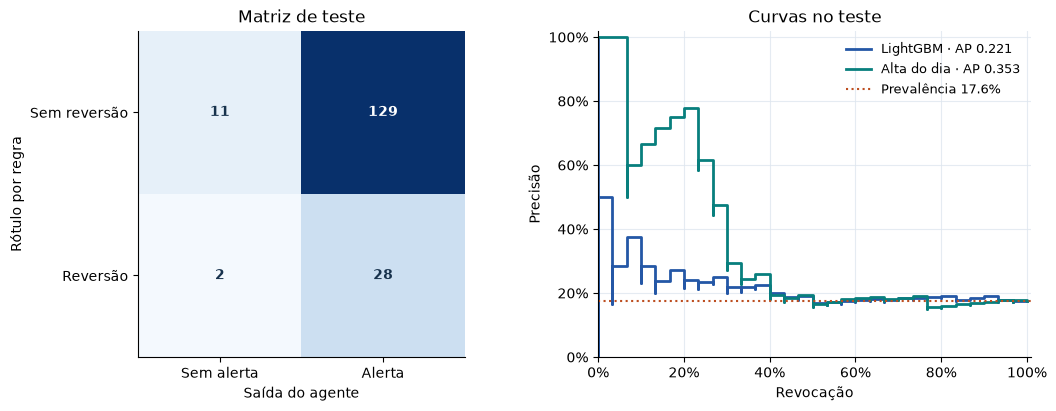

In [7]:
fig, (matrix_ax, curve_ax) = plt.subplots(1, 2, figsize=(10.5, 4), layout="constrained")
matrix_ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(1, matrix.max()))
for (row, column), value in np.ndenumerate(matrix):
    matrix_ax.text(
        column, row, str(value), ha="center", va="center", weight="bold",
        color="white" if value > matrix.max() / 2 else "#17324d",
    )
matrix_ax.set(
    xticks=[0, 1], xticklabels=["Sem alerta", "Alerta"],
    yticks=[0, 1], yticklabels=["Sem reversão", "Reversão"],
    xlabel="Saída do agente", ylabel="Rótulo por regra", title="Matriz de teste",
)
matrix_ax.grid(False)

for name, scores, color in [
    ("LightGBM", test["score"], BLUE), ("Alta do dia", test["return_1d"], TEAL)
]:
    p_curve, r_curve, _ = precision_recall_curve(actual, scores)
    ap = average_precision_score(actual, scores)
    curve_ax.step(r_curve, p_curve, where="post", lw=2, color=color, label=f"{name} · AP {ap:.3f}")
curve_ax.axhline(prevalence, color=ORANGE, ls=":", label=f"Prevalência {prevalence:.1%}")
curve_ax.set(xlim=(0, 1.01), ylim=(0, 1.02), xlabel="Revocação", ylabel="Precisão", title="Curvas no teste")
for axis in (curve_ax.xaxis, curve_ax.yaxis):
    axis.set_major_formatter(PercentFormatter(1, decimals=0))
curve_ax.legend(loc="upper right", frameon=False, fontsize=9)
plt.show()

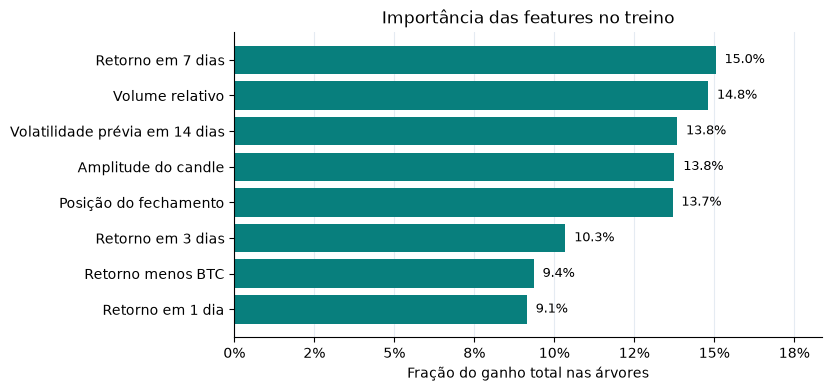

In [8]:
gain = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=FEATURES)
share = (gain / gain.sum() if gain.sum() else gain).rename(index=FEATURE_NAMES).sort_values()

fig, ax = plt.subplots(figsize=(8.2, 3.8), layout="constrained")
ax.barh(share.index, share, color=TEAL)
upper = max(0.10, float(share.max()) * 1.22)
ax.set(
    xlim=(0, upper),
    xlabel="Fração do ganho total nas árvores", title="Importância das features no treino",
)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
for index, value in enumerate(share):
    ax.text(value + upper * 0.015, index, f"{value:.1%}", va="center", fontsize=9)
plt.show()

## 6. Simular uma consulta ao agente diário

A consulta recebe um ativo e uma data. O grafo coleta as features disponíveis naquele fechamento, verifica o gatilho, aplica o modelo e explica o resultado localmente. O exemplo usa o mesmo dia mostrado no gráfico. O estado do agente recebe apenas as colunas de inferência.

In [9]:
class DailyState(TypedDict, total=False):
    symbol: str
    date: str
    evidence: dict | None
    score: float | None
    status: str
    explanation: str


signals = panel.set_index(["symbol", "date"])[[*FEATURES, "candidate", "scorable"]]


def collect(state):
    key = (state["symbol"].upper(), pd.to_datetime(state["date"], utc=True).normalize())
    row = signals.loc[key, :] if key in signals.index else None
    return {"evidence": None if row is None else row.to_dict()}


def assess(state):
    evidence = state["evidence"]
    if evidence is None or not evidence["scorable"]:
        return {"status": "SEM_COBERTURA", "score": None}
    if not evidence["candidate"]:
        return {"status": "SEM_GATILHO", "score": None}
    score = float(model.predict_proba(pd.DataFrame([evidence])[FEATURES])[0, 1])
    return {"status": "ALERTA_REVERSAO" if score >= threshold else "ABAIXO_LIMIAR", "score": score}


def explain(state):
    status, score = state["status"], state["score"]
    if score is None:
        messages = {
            "SEM_COBERTURA": "Dados insuficientes para a análise diária.",
            "SEM_GATILHO": "A alta ou o volume ficaram abaixo do gatilho diário.",
        }
        return {"explanation": messages[status]}
    evidence = state["evidence"]
    return {"explanation": (
        f"Alta de {evidence['return_1d']:.1%} e volume {evidence['relative_volume']:.2f}× a mediana. "
        f"Score de reversão {score:.3f} com limiar {threshold:.3f}."
    )}


graph = StateGraph(DailyState)
graph.add_node("collect", collect)
graph.add_node("assess", assess)
graph.add_node("explain", explain)
graph.add_edge(START, "collect")
graph.add_edge("collect", "assess")
graph.add_edge("assess", "explain")
graph.add_edge("explain", END)
agent = graph.compile()

result = agent.invoke({"symbol": str(symbol), "date": day.date().isoformat()})
display(pd.Series({key: result[key] for key in ("symbol", "date", "status", "score", "explanation")}))
assert np.isclose(result["score"], example["score"])

symbol                                                      DOGE
date                                                  2020-07-08
status                                           ALERTA_REVERSAO
score                                                   0.090385
explanation    Alta de 53.7% e volume 7.10× a mediana. Score ...
dtype: object

### Limites do experimento

O conjunto termina em 2021 e reúne um universo selecionado de ativos. Quedas de mercado, notícias ou correções legítimas podem satisfazer a regra. As métricas medem a capacidade de antecipar a reversão definida pela regra em datas fora do treino. A unidade de avaliação é o dia por ativo. Dias consecutivos podem fazer parte do mesmo episódio. Uma avaliação de manipulação precisaria de eventos confirmados, mercado de execução identificado e dados intradiários.